# CSET485 Assignment 1 — Adult income model audit
**Vaibhav Bedi · S24CSEU0158 · seed 158**

Run all cells from top to bottom. The notebook downloads the original UCI files if `data/` is absent and exports every result to `results/`. The supplied ZIP includes the source data for offline reproduction.

The outcome is `income > $50K`, not recidivism, danger, repayment, or merit. Models A and B use the same 70/30 stratified split. The separate descriptive subgroup analysis uses the full cleaned cohort as requested and does not train or tune the test-set predictor.

## Environment
Use Python 3.12 and install `requirements.txt`. This notebook uses only the standard Python scientific stack. The PDF explains the modeling assumptions and the limits of causal and fairness interpretations.

## Methods chosen before reporting
Exact duplicate removal; training-only category pooling (<100 observations); missing categories retained; log1p of final weight and capital gain/loss; standardized numeric predictors; one-hot categorical predictors; OLS and L2 logistic regression (C=1). The ordinal education-num representation retains the education information without a duplicate column. Subgroup confidence intervals use separate unpenalized explanatory logistic models with HC1 robust covariance; six slope comparisons receive Holm correction. The predictive model is never reselected using the test sweep.


## Imports and reproducibility

In [1]:
from pathlib import Path
import json, hashlib, urllib.request, platform, warnings
import numpy as np
import pandas as pd
import scipy
from scipy.stats import norm
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score, brier_score_loss
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
SEED = 158
ROOT = Path.cwd()
DATA = ROOT / 'data'; DATA.mkdir(exist_ok=True)
OUT = ROOT / 'results'; OUT.mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False})



## Obtain and clean the original UCI files

In [2]:
BASE = 'https://archive.ics.uci.edu/ml/machine-learning-databases/adult/'
COLS = ['age','workclass','fnlwgt','education','education-num','marital-status','occupation','relationship','race','sex','capital-gain','capital-loss','hours-per-week','native-country','income']
frames=[]; hashes={}
for filename in ['adult.data','adult.test']:
    path=DATA/filename
    if not path.exists(): path.write_bytes(urllib.request.urlopen(BASE+filename,timeout=60).read())
    hashes[filename]=hashlib.sha256(path.read_bytes()).hexdigest()
    frame=pd.read_csv(path,names=COLS,skipinitialspace=True,na_values='?',comment='|')
    frame['income']=frame['income'].str.strip().str.rstrip('.')
    frame['source_file']=filename
    frame['source_row']=np.arange(1,len(frame)+1)
    frames.append(frame)
raw=pd.concat(frames,ignore_index=True)
raw['record_id']=np.arange(1,len(raw)+1)
missing=raw[COLS].isna().sum().to_dict()
duplicate_count=int(raw.duplicated(COLS).sum())
# Exact duplicates are removed before splitting; source identifiers are never features.
df=raw.drop_duplicates(COLS).copy().set_index('record_id')
y=(df['income']=='>50K').astype(int)
train_ids,test_ids=train_test_split(df.index,test_size=.30,random_state=SEED,stratify=y)
train=df.loc[train_ids].copy(); test=df.loc[test_ids].copy()
ytr=y.loc[train_ids]; yte=y.loc[test_ids]
assert set(train_ids).isdisjoint(test_ids)
# education is a deterministic duplicate of education-num; retain numeric representation.
assert df.groupby('education')['education-num'].nunique().max()==1
num_cols=['age','education-num','hours-per-week','fnlwgt','capital-gain','capital-loss']
cat_cols=['workclass','marital-status','occupation','relationship','race','sex','native-country']



## Preprocessing fitted on training data only

In [3]:
medians=train[num_cols].median()
def numeric(frame):
    v=frame[num_cols].fillna(medians).astype(float).copy()
    for c in ['fnlwgt','capital-gain','capital-loss']:v[c]=np.log1p(v[c])
    return v
scaler=StandardScaler().fit(numeric(train))
retained={c:set(train[c].fillna('Missing').value_counts().loc[lambda s:s>=100].index) for c in cat_cols}
def categorical(frame):
    v=frame[cat_cols].fillna('Missing').copy()
    for c in cat_cols:v[c]=v[c].where(v[c].isin(retained[c]),'OtherRare')
    return v
enc=OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False).fit(categorical(train))
names=['z_'+c for c in num_cols]+list(enc.get_feature_names_out(cat_cols))
def design(frame):
    a=np.column_stack([scaler.transform(numeric(frame)),enc.transform(categorical(frame))])
    return sm.add_constant(pd.DataFrame(a,index=frame.index,columns=names),has_constant='add')
Xtr=design(train);Xte=design(test)
assert np.linalg.matrix_rank(Xtr.to_numpy())==Xtr.shape[1]
# Outliers retained. log1p reduces numerical skew, then z scores use training means/SDs.
# fnlwgt is used as a predictor, not a sample weight. These are sample-level results.
preprocessing={'raw_n':len(raw),'deduplicated_n':len(df),'duplicates_removed':duplicate_count,'train_n':len(train),'test_n':len(test),'missing_raw':missing,'positive_train':int(ytr.sum()),'positive_test':int(yte.sum()),'predictor_columns':len(names),'hashes':hashes,'category_reference':dict(zip(cat_cols,[str(x[0]) for x in enc.categories_])),'retained_categories':{k:sorted(v) for k,v in retained.items()},'numeric_means':dict(zip(num_cols,scaler.mean_)),'numeric_sd':dict(zip(num_cols,scaler.scale_))}
print('PREPROCESSING',preprocessing)


PREPROCESSING {'raw_n': 48842, 'deduplicated_n': 48790, 'duplicates_removed': 52, 'train_n': 34153, 'test_n': 14637, 'missing_raw': {'age': 0, 'workclass': 2799, 'fnlwgt': 0, 'education': 0, 'education-num': 0, 'marital-status': 0, 'occupation': 2809, 'relationship': 0, 'race': 0, 'sex': 0, 'capital-gain': 0, 'capital-loss': 0, 'hours-per-week': 0, 'native-country': 857, 'income': 0}, 'positive_train': 8177, 'positive_test': 3504, 'predictor_columns': 52, 'hashes': {'adult.data': '5b00264637dbfec36bdeaab5676b0b309ff9eb788d63554ca0a249491c86603d', 'adult.test': 'a2a9044bc167a35b2361efbabec64e89d69ce82d9790d2980119aac5fd7e9c05'}, 'category_reference': {'workclass': 'Federal-gov', 'marital-status': 'Divorced', 'occupation': 'Adm-clerical', 'relationship': 'Husband', 'race': 'Amer-Indian-Eskimo', 'sex': 'Female', 'native-country': 'Canada'}, 'retained_categories': {'workclass': ['Federal-gov', 'Local-gov', 'Missing', 'Private', 'Self-emp-inc', 'Self-emp-not-inc', 'State-gov'], 'marital-sta

## Part 1 Model fitting

In [4]:
ols=sm.OLS(ytr,Xtr).fit()
# L2 logistic stabilizes sparse/near-collinear categorical levels. Intercept is unpenalized.
clf=LogisticRegression(C=1.0,solver='lbfgs',max_iter=3000,tol=1e-9,random_state=SEED)
clf.fit(Xtr.drop(columns='const'),ytr)
assert clf.n_iter_[0]<clf.max_iter
beta=pd.Series(np.r_[clf.intercept_,clf.coef_[0]],index=Xtr.columns)
pa=ols.predict(Xte);pb=pd.Series(clf.predict_proba(Xte.drop(columns='const'))[:,1],index=test.index)
median=float(np.median(pa));ca=(pa>=median).astype(int);cb=(pb>=.5).astype(int)
agreement=confusion_matrix(ca,cb,labels=[0,1]);mismatch=int((ca!=cb).sum())
part1={'median_ols':median,'agreement':agreement.tolist(),'mismatch_n':mismatch,'mismatch_pct':100*mismatch/len(test),'ols_positive_n':int(ca.sum()),'logit_positive_n':int(cb.sum()),'ols_accuracy':accuracy_score(yte,ca),'logit_accuracy':accuracy_score(yte,cb),'logit_auc':roc_auc_score(yte,pb),'logit_brier':brier_score_loss(yte,pb),'ols_outside_0_1_n':int(((pa<0)|(pa>1)).sum()),'ols_min':float(pa.min()),'ols_max':float(pa.max()),'ols_confusion_truth':confusion_matrix(yte,ca).tolist(),'logit_confusion_truth':confusion_matrix(yte,cb).tolist(),'logit_converged':bool(clf.n_iter_[0]<clf.max_iter)}
print('PART1',part1)
coefs=pd.DataFrame({'coefficient':beta});coefs.to_csv(OUT/'baseline_coefficients.csv')
pred=test.copy();pred['actual']=yte;pred['ols_score']=pa;pred['logit_probability']=pb;pred['ols_class']=ca;pred['logit_class']=cb
pred.to_csv(OUT/'test_predictions.csv')


PART1 {'median_ols': 0.22861886697660475, 'agreement': [[7318, 0], [4390, 2929]], 'mismatch_n': 4390, 'mismatch_pct': 29.99248479879757, 'ols_positive_n': 7319, 'logit_positive_n': 2929, 'ols_accuracy': 0.7125777140124342, 'logit_accuracy': 0.8482612557218009, 'logit_auc': 0.9015702422392272, 'logit_brier': 0.10474950072875625, 'ols_outside_0_1_n': 3172, 'ols_min': -0.3831755387934186, 'ols_max': 1.159038949002519, 'ols_confusion_truth': [[7122, 4011], [196, 3308]], 'logit_confusion_truth': [[10310, 823], [1398, 2106]], 'logit_converged': True}


## Part 2.1 Exploratory subgroup analysis on full cleaned cohort

In [5]:
# Explanatory fits never change the predictive model or its held-out predictions.
Z=pd.DataFrame({'age':df.age,'education_num':df['education-num'],'hours_per_week':df['hours-per-week'],'log_capital_gain':np.log1p(df['capital-gain']),'log_capital_loss':np.log1p(df['capital-loss']),'married':(df['marital-status']=='Married-civ-spouse').astype(int),'male':(df.sex=='Male').astype(int)},index=df.index,dtype=float)
pooled=sm.GLM(y,sm.add_constant(Z),family=sm.families.Binomial()).fit(cov_type='HC1')
subfits={}
for sex in ['Female','Male']:
    mask=df.sex.eq(sex)
    subfits[sex]=sm.GLM(y.loc[mask],sm.add_constant(Z.loc[mask].drop(columns='male')),family=sm.families.Binomial()).fit(cov_type='HC1')
rows=[]
for key in Z.columns.drop('male'):
    a,b=subfits['Female'],subfits['Male'];delta=float(a.params[key]-b.params[key]);se=float(np.sqrt(a.bse[key]**2+b.bse[key]**2));pv=2*norm.sf(abs(delta/se))
    row={'predictor':key,'pooled':pooled.params[key],'female':a.params[key],'male':b.params[key],'difference_F_minus_M':delta,'difference_ci_low':delta-1.96*se,'difference_ci_high':delta+1.96*se,'p_difference':pv}
    for label,fit in [('pooled',pooled),('female',a),('male',b)]:row[label+'_ci_low'],row[label+'_ci_high']=fit.conf_int().loc[key]
    rows.append(row)
subgroup=pd.DataFrame(rows);subgroup['p_holm']=multipletests(subgroup.p_difference,method='holm')[1]
subgroup.to_csv(OUT/'subgroup_effects.csv',index=False);print('SUBGROUP\n',subgroup.to_string(index=False))


SUBGROUP
        predictor   pooled   female     male  difference_F_minus_M  difference_ci_low  difference_ci_high  p_difference  pooled_ci_low  pooled_ci_high  female_ci_low  female_ci_high  male_ci_low  male_ci_high       p_holm
             age 0.026945 0.035229 0.027114              0.008116           0.002819            0.013413  2.673546e-03       0.024777        0.029114       0.030563        0.039896     0.024607      0.029621 8.020638e-03
   education_num 0.368826 0.440060 0.355404              0.084656           0.050055            0.119258  1.623853e-06       0.356433        0.381220       0.408130        0.471990     0.342073      0.368734 8.119264e-06
  hours_per_week 0.031725 0.035159 0.032135              0.003024          -0.003171            0.009218  3.387566e-01       0.029262        0.034188       0.029613        0.040704     0.029375      0.034895 6.775132e-01
log_capital_gain 0.210904 0.245753 0.199048              0.046705           0.021525            0.071885  

## Part 2.2 Omitted variable sensitivity

In [6]:
Xred=Xtr.drop(columns='z_education-num')
reduced=LogisticRegression(C=1.0,solver='lbfgs',max_iter=3000,tol=1e-9,random_state=SEED).fit(Xred.drop(columns='const'),ytr)
assert reduced.n_iter_[0]<reduced.max_iter
reduced_beta=pd.Series(np.r_[reduced.intercept_,reduced.coef_[0]],index=Xred.columns)
shared=beta.index.intersection(reduced_beta.index).drop('const')
omit=pd.DataFrame({'full':beta[shared],'reduced':reduced_beta[shared]})
omit['delta']=omit.reduced-omit.full;omit['pct_change_signed']=100*omit.delta/omit.full
omit['absolute_pct_change']=omit.pct_change_signed.abs();omit['absolute_shift']=omit.delta.abs();omit.to_csv(OUT/'omitted_variable_all_coefficients.csv')
key_predictors=['z_age','z_hours-per-week','z_capital-gain','z_capital-loss']
omit_key=omit.loc[key_predictors];omit_key.to_csv(OUT/'omitted_variable_four_predictors.csv')
print('OMITTED FOUR\n',omit_key.to_string());print('LARGEST ABS\n',omit.sort_values('absolute_shift',ascending=False).head(3).to_string());print('LARGEST PCT\n',omit.sort_values('absolute_pct_change',ascending=False).head(3).to_string())


OMITTED FOUR
                       full   reduced     delta  pct_change_signed  absolute_pct_change  absolute_shift
z_age             0.343524  0.283639 -0.059885         -17.432634            17.432634        0.059885
z_hours-per-week  0.360834  0.372526  0.011692           3.240279             3.240279        0.011692
z_capital-gain    0.498834  0.504895  0.006061           1.215086             1.215086        0.006061
z_capital-loss    0.216739  0.230615  0.013876           6.402316             6.402316        0.013876
LARGEST ABS
                                  full   reduced     delta  pct_change_signed  absolute_pct_change  absolute_shift
occupation_Prof-specialty    0.623806  1.301695  0.677889         108.669939           108.669939        0.677889
native-country_Mexico       -0.811150 -1.446539 -0.635389          78.331770            78.331770        0.635389
occupation_Transport-moving -0.038350 -0.453655 -0.415305        1082.927932          1082.927932        0.415305
LA

## Part 2.3 High confidence errors and seeded sample

In [7]:
wrong=((pb>=.75)&(yte==0))|((pb<=.25)&(yte==1))
wrong_all=pred.loc[wrong].copy();adv=wrong_all.sample(n=min(50,len(wrong_all)),random_state=SEED).copy()
wrong_all.to_csv(OUT/'all_high_confidence_errors.csv');adv.to_csv(OUT/'adversarial_50.csv')
def describe_group(frame):
    return {'n':len(frame),'age_mean':float(frame.age.mean()),'age_median':float(frame.age.median()),'age_min':int(frame.age.min()),'age_max':int(frame.age.max()),'female_pct':100*frame.sex.eq('Female').mean(),'male_pct':100*frame.sex.eq('Male').mean(),'white_pct':100*frame.race.eq('White').mean(),'married_pct':100*frame['marital-status'].eq('Married-civ-spouse').mean(),'zero_gain_pct':100*frame['capital-gain'].eq(0).mean(),'zero_loss_pct':100*frame['capital-loss'].eq(0).mean(),'education_ge13_pct':100*frame['education-num'].ge(13).mean(),'hours_ge40_pct':100*frame['hours-per-week'].ge(40).mean(),'positive_actual_pct':100*frame.actual.mean()}
demo=pd.DataFrame({'test':describe_group(pred),'all_errors':describe_group(wrong_all),'sample50':describe_group(adv)});demo.to_csv(OUT/'adversarial_demographics.csv')
contrib=Xte.loc[adv.index].mul(beta,axis=1);contrib.to_csv(OUT/'adversarial_logodds_contributions.csv')
assert np.allclose(contrib.sum(axis=1),np.log(adv.logit_probability/(1-adv.logit_probability)))
adv_stats={'total_n':int(wrong.sum()),'pct_test':100*wrong.mean(),'confident_fp':int(((pb>=.75)&(yte==0)).sum()),'confident_fn':int(((pb<=.25)&(yte==1)).sum()),'sample_fp':int(((adv.logit_probability>=.75)&(adv.actual==0)).sum()),'sample_fn':int(((adv.logit_probability<=.25)&(adv.actual==1)).sum()),'sample_n':len(adv)}
print('ADVERSARIAL',adv_stats);print(demo.to_string())


ADVERSARIAL {'total_n': 751, 'pct_test': np.float64(5.130832820933252), 'confident_fp': 176, 'confident_fn': 575, 'sample_fp': 7, 'sample_fn': 43, 'sample_n': 50}
                             test  all_errors  sample50
n                    14637.000000  751.000000     50.00
age_mean                38.734099   43.729694     42.92
age_median              37.000000   42.000000     41.00
age_min                 17.000000   19.000000     22.00
age_max                 90.000000   90.000000     71.00
female_pct              32.943909   22.902796     18.00
male_pct                67.056091   77.097204     82.00
white_pct               85.857758   86.284953     94.00
married_pct             46.238983   63.648469     64.00
zero_gain_pct           91.951903   88.948069     90.00
zero_loss_pct           95.060463   94.141145     96.00
education_ge13_pct      24.656692   32.490013     20.00
hours_ge40_pct          76.333948   86.684421     84.00
positive_actual_pct     23.939332   76.564581     86.

## Part 2.4 Fairness sweep A Female B Male

In [8]:
# Income prediction is not a risk or creditworthiness label.
def div(a,b):return float(a/b) if np.isfinite(b) and b!=0 else np.nan
def rates(truth,proba,t):
    labels=(proba>=t).astype(int);tn,fp,fn,tp=confusion_matrix(truth,labels,labels=[0,1]).ravel()
    return {'n':len(truth),'positive_n':int(labels.sum()),'tp':int(tp),'fp':int(fp),'fn':int(fn),'tn':int(tn),'selection_rate':float(labels.mean()),'tpr':div(tp,tp+fn),'fpr':div(fp,fp+tn),'ppv':div(tp,tp+fp),'accuracy':float((labels==truth).mean()),'base_rate':float(truth.mean())}
thresholds=np.round(np.arange(.05,1,.1),2);fair=[]
for t in thresholds:
    female=test.sex.eq('Female');male=test.sex.eq('Male');a=rates(yte[female],pb[female],t);b=rates(yte[male],pb[male],t)
    tr,fr=div(a['tpr'],b['tpr']),div(a['fpr'],b['fpr'])
    row={'threshold':float(t),'DP':div(a['selection_rate'],b['selection_rate']),'EO':min(tr,fr) if np.isfinite([tr,fr]).all() else np.nan,'PP':div(a['ppv'],b['ppv']),'TPR_ratio':tr,'FPR_ratio':fr,'accuracy':accuracy_score(yte,pb>=t)}
    row.update({'F_'+k:v for k,v in a.items()});row.update({'M_'+k:v for k,v in b.items()});fair.append(row)
fair=pd.DataFrame(fair);fair.to_csv(OUT/'fairness_thresholds.csv',index=False)
print('FAIRNESS\n',fair[['threshold','DP','EO','PP','TPR_ratio','FPR_ratio','accuracy','F_tpr','M_tpr','F_fpr','M_fpr','F_ppv','M_ppv']].to_string(index=False))
fig,ax=plt.subplots(figsize=(7,5));ax.plot(fair.DP,fair.EO,'o-',color='#28647d',lw=1.5)
for _,r in fair.iterrows():ax.annotate(f"{r.threshold:.2f}",(r.DP,r.EO),xytext=(5,5),textcoords='offset points',fontsize=8)
ax.axvline(1,color='#777',ls='--',lw=.8);ax.axhline(1,color='#777',ls='--',lw=.8)
ax.set(xlim=(0,1.5),ylim=(0,1.5),xlabel='Demographic parity ratio  Female / Male',ylabel='Equalized odds index specified in assignment',title='Threshold sweep on the held-out Adult test set');ax.grid(alpha=.15);fig.tight_layout();fig.savefig(OUT/'fairness_tradeoff.png',dpi=200);plt.close(fig)
fig,ax=plt.subplots(figsize=(7,4))
for col in ['DP','EO','PP']:ax.plot(fair.threshold,fair[col],marker='o',label=col)
ax.axhline(1,color='#777',ls='--',lw=.8);ax.set(xlabel='Decision threshold',ylabel='Female / Male ratio',title='Three fairness measures across thresholds');ax.legend();ax.grid(alpha=.15);fig.tight_layout();fig.savefig(OUT/'fairness_by_threshold.png',dpi=200);plt.close(fig)
fig,ax=plt.subplots(figsize=(5,3));ax.imshow(agreement,cmap='Blues')
for (i,j),v in np.ndenumerate(agreement):ax.text(j,i,str(v),ha='center',va='center',color='white' if v>agreement.max()/2 else 'black',fontsize=14)
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Logistic 0','Logistic 1'],yticklabels=['OLS 0','OLS 1'],title='Agreement between the two decision rules');fig.tight_layout();fig.savefig(OUT/'agreement_matrix.png',dpi=200);plt.close(fig)


FAIRNESS
  threshold       DP       EO       PP  TPR_ratio  FPR_ratio  accuracy    F_tpr    M_tpr    F_fpr    M_fpr    F_ppv    M_ppv
      0.05 0.493335 0.467629 0.686955   0.955437   0.467629  0.616042 0.944231 0.988271 0.293817 0.628312 0.279772 0.407264
      0.15 0.336983 0.281665 0.926459   0.880170   0.281665  0.749402 0.828846 0.941689 0.119247 0.423364 0.456568 0.492810
      0.25 0.307111 0.250932 0.964228   0.834849   0.250932  0.808021 0.715385 0.856903 0.070897 0.282535 0.549483 0.569869
      0.35 0.301571 0.249749 0.964645   0.820143   0.249749  0.834529 0.621154 0.757373 0.047420 0.189870 0.612903 0.635367
      0.45 0.292616 0.232017 0.992722   0.818950   0.232017  0.846280 0.542308 0.662198 0.029754 0.128239 0.687805 0.692847
      0.55 0.280846 0.214651 1.006850   0.797195   0.214651  0.848603 0.455769 0.571716 0.018131 0.084468 0.752381 0.747262
      0.65 0.279026 0.227488 0.988407   0.777524   0.227488  0.838696 0.353846 0.455094 0.011623 0.051091 0.786325 0.79554

## Export evidence and verify consistency

In [9]:
versions={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,'sklearn':sklearn.__version__,'statsmodels':sm.__version__,'matplotlib':matplotlib.__version__}
results={'seed':SEED,'preprocessing':preprocessing,'part1':part1,'adversarial':adv_stats,'versions':versions}
(OUT/'summary.json').write_text(json.dumps(results,indent=2));(OUT/'train_record_ids.json').write_text(json.dumps([int(i) for i in train_ids]));(OUT/'test_record_ids.json').write_text(json.dumps([int(i) for i in test_ids]))
assert agreement.sum()==len(test)
assert mismatch==agreement[0,1]+agreement[1,0]
assert len(adv)==min(50,int(wrong.sum()))
assert set(adv.index).issubset(set(test.index))
assert len(fair)==10 and np.isfinite(beta).all()
print('Completed: all consistency checks passed')


Completed: all consistency checks passed


## Additional report evidence and case examples

In [10]:
hi=fair.set_index('threshold').loc[.85];lo=fair.set_index('threshold').loc[.75]
z_gain=100*(lo.DP-hi.DP)/hi.DP;w_loss=100*(hi.EO-lo.EO)/hi.EO
case_ids=[534,40829]
cases=pred.loc[case_ids,['age','sex','education-num','hours-per-week','actual','logit_probability']].copy()
assert (cases.logit_probability.ge(.75)&cases.logit_probability.lt(.85)).all()
cases['class_at_085']=(cases.logit_probability>=.85).astype(int);cases['class_at_075']=(cases.logit_probability>=.75).astype(int)
cases.to_csv(OUT/'fairness_case_examples.csv')
row1532=adv.loc[1532];c1532=contrib.loc[1532]
evidence={'tradeoff':{'from_threshold':.85,'to_threshold':.75,'dp_gain_pct':float(z_gain),'eo_loss_pct':float(w_loss),'cost_W_over_Z':float(w_loss/z_gain)},'subgroup_n':df.sex.value_counts().to_dict(),'education_odds_ratios':{k:float(np.exp(v.params['education_num'])) for k,v in subfits.items()},'case1532':{'probability':float(row1532.logit_probability),'log_odds':float(c1532.sum()),'education_contribution':float(c1532['z_education-num']),'occupation_contribution':float(c1532['occupation_Machine-op-inspct'])},'missing_any_raw':int(raw[COLS].isna().any(axis=1).sum()),'ols_selection_pct':float(100*ca.mean()),'logistic_selection_pct':float(100*cb.mean()),'zero_classifier_accuracy':float(1-yte.mean())}
(OUT/'report_evidence.json').write_text(json.dumps(evidence,indent=2))
print('ADDITIONAL REPORT EVIDENCE',evidence)
print(cases.to_string())
# Recreate the required 0-1.5 chart with separated labels and leader lines.
fig,ax=plt.subplots(figsize=(7.2,5.3));ax.plot(fair.DP,fair.EO,'o-',color='#245b73',lw=1.4)
label_order=[.05,.85,.15,.75,.25,.35,.45,.65,.55,.95]
for i,t in enumerate(label_order):
    r=fair.set_index('threshold').loc[t]
    ax.annotate(f't = {t:.2f}',(r.DP,r.EO),xytext=(.72,1.36-i*.13),textcoords='data',fontsize=9,arrowprops={'arrowstyle':'-','lw':.65,'color':'#888'})
ax.axvline(1,color='#aaa',ls='--',lw=.8);ax.axhline(1,color='#aaa',ls='--',lw=.8)
ax.set(xlim=(0,1.5),ylim=(0,1.5),xlabel='Demographic parity ratio  Female / Male',ylabel='Equalized odds index specified in assignment',title='Fairness trade-off across ten thresholds');ax.grid(alpha=.15)
fig.tight_layout();fig.savefig(OUT/'fairness_tradeoff.png',dpi=200);plt.close(fig)
print('Final evidence and charts saved')


ADDITIONAL REPORT EVIDENCE {'tradeoff': {'from_threshold': 0.85, 'to_threshold': 0.75, 'dp_gain_pct': 4.217088375504213, 'eo_loss_pct': 22.807017543859647, 'cost_W_over_Z': 5.408237986270028}, 'subgroup_n': {'Male': 32614, 'Female': 16176}, 'education_odds_ratios': {'Female': 1.5527999749260557, 'Male': 1.4267563713355715}, 'case1532': {'probability': 0.08340772776976062, 'log_odds': -2.3969217769500917, 'education_contribution': -1.1550954359623191, 'occupation_contribution': -0.29282079901280883}, 'missing_any_raw': 3620, 'ols_selection_pct': 50.003416000546565, 'logistic_selection_pct': 20.010931201748992, 'zero_classifier_accuracy': 0.7606066816970691}
           age     sex  education-num  hours-per-week  actual  logit_probability  class_at_085  class_at_075
record_id                                                                                                   
534         41  Female             12              50       1           0.771157             0             1
40829   

## Inspect the exported evidence
All displayed tables are computed above. The requested equalized-odds index is the smaller of two ratios; inspect both component ratios as well. Undefined denominators return NaN, never an invented zero. The two fee-assessment examples in the report are hypothetical uses of real test rows, not observed decisions.

,predictor,pooled,female,male,difference_F_minus_M,difference_ci_low,difference_ci_high,p_difference,pooled_ci_low,pooled_ci_high,female_ci_low,female_ci_high,male_ci_low,male_ci_high,p_holm
0,age,0.026945,0.035229,0.027114,0.008116,0.002819,0.013413,0.002674,0.024777,0.029114,0.030563,0.039896,0.024607,0.029621,0.008021
1,education_num,0.368826,0.440060,0.355404,0.084656,0.050055,0.119258,0.000002,0.356433,0.381220,0.408130,0.471990,0.342073,0.368734,0.000008
2,hours_per_week,0.031725,0.035159,0.032135,0.003024,-0.003171,0.009218,0.338757,0.029262,0.034188,0.029613,0.040704,0.029375,0.034895,0.677513
3,log_capital_gain,0.210904,0.245753,0.199048,0.046705,0.021525,0.071885,0.000277,0.200659,0.221149,0.223245,0.268261,0.187761,0.210335,0.001110
4,log_capital_loss,0.158703,0.156401,0.157212,-0.000811,-0.038139,0.036518,0.966053,0.144362,0.173044,0.122594,0.190209,0.141389,0.173035,0.966053
5,married,2.346995,3.162143,2.040522,1.121622,0.960452,1.282791,0.000000,2.275026,2.418965,3.021524,3.302762,1.961776,2.119267,0.000000


,full,reduced,delta,pct_change_signed,absolute_pct_change,absolute_shift
z_age,0.343524,0.283639,-0.059885,-17.432634,17.432634,0.059885
z_hours-per-week,0.360834,0.372526,0.011692,3.240279,3.240279,0.011692
z_capital-gain,0.498834,0.504895,0.006061,1.215086,1.215086,0.006061
z_capital-loss,0.216739,0.230615,0.013876,6.402316,6.402316,0.013876


,test,all_errors,sample50
n,14637.000,751.000,50.00
age_mean,38.734,43.730,42.92
age_median,37.000,42.000,41.00
age_min,17.000,19.000,22.00
age_max,90.000,90.000,71.00
female_pct,32.944,22.903,18.00
male_pct,67.056,77.097,82.00
white_pct,85.858,86.285,94.00
married_pct,46.239,63.648,64.00
zero_gain_pct,91.952,88.948,90.00


,threshold,DP,EO,PP,TPR_ratio,FPR_ratio,accuracy,F_n,F_positive_n,F_tp,F_fp,F_fn,F_tn,F_selection_rate,F_tpr,F_fpr,F_ppv,F_accuracy,F_base_rate,M_n,M_positive_n,M_tp,M_fp,M_fn,M_tn,M_selection_rate,M_tpr,M_fpr,M_ppv,M_accuracy,M_base_rate
0,0.05,0.493335,0.467629,0.686955,0.955437,0.467629,0.616042,4822,1755,491,1264,29,3038,0.363957,0.944231,0.293817,0.279772,0.731854,0.107839,9815,7241,2949,4292,35,2539,0.737748,0.988271,0.628312,0.407264,0.559144,0.304024
1,0.15,0.336983,0.281665,0.926459,0.880170,0.281665,0.749402,4822,944,431,513,89,3789,0.195769,0.828846,0.119247,0.456568,0.875156,0.107839,9815,5702,2810,2892,174,3939,0.580948,0.941689,0.423364,0.492810,0.687621,0.304024
2,0.25,0.307111,0.250932,0.964228,0.834849,0.250932,0.808021,4822,677,372,305,148,3997,0.140398,0.715385,0.070897,0.549483,0.906056,0.107839,9815,4487,2557,1930,427,4901,0.457157,0.856903,0.282535,0.569869,0.759857,0.304024
3,0.35,0.301571,0.249749,0.964645,0.820143,0.249749,0.834529,4822,527,323,204,197,4098,0.109291,0.621154,0.047420,0.612903,0.916839,0.107839,9815,3557,2260,1297,724,5534,0.362404,0.757373,0.189870,0.635367,0.794091,0.304024
4,0.45,0.292616,0.232017,0.992722,0.818950,0.232017,0.846280,4822,410,282,128,238,4174,0.085027,0.542308,0.029754,0.687805,0.924098,0.107839,9815,2852,1976,876,1008,5955,0.290576,0.662198,0.128239,0.692847,0.808049,0.304024
5,0.55,0.280846,0.214651,1.006850,0.797195,0.214651,0.848603,4822,315,237,78,283,4224,0.065326,0.455769,0.018131,0.752381,0.925135,0.107839,9815,2283,1706,577,1278,6254,0.232603,0.571716,0.084468,0.747262,0.811004,0.304024
6,0.65,0.279026,0.227488,0.988407,0.777524,0.227488,0.838696,4822,234,184,50,336,4252,0.048528,0.353846,0.011623,0.786325,0.919950,0.107839,9815,1707,1358,349,1626,6482,0.173917,0.455094,0.051091,0.795548,0.798777,0.304024
7,0.75,0.282143,0.250716,0.977953,0.777894,0.250716,0.822983,4822,154,130,24,390,4278,0.031937,0.250000,0.005579,0.844156,0.914144,0.107839,9815,1111,959,152,2025,6679,0.113194,0.321381,0.022252,0.863186,0.778197,0.304024
8,0.85,0.270727,0.324791,0.958112,0.731273,0.324791,0.800506,4822,81,72,9,448,4293,0.016798,0.138462,0.002092,0.888889,0.905226,0.107839,9815,609,565,44,2419,6787,0.062048,0.189343,0.006441,0.927750,0.749058,0.304024
9,0.95,0.250351,0.000000,1.033149,0.729197,0.000000,0.774134,4822,23,23,0,497,4302,0.004770,0.044231,0.000000,1.000000,0.896931,0.107839,9815,187,181,6,2803,6825,0.019052,0.060657,0.000878,0.967914,0.713805,0.304024


,age,sex,education-num,hours-per-week,actual,logit_probability,class_at_085,class_at_075
record_id,,,,,,,,
534,41,Female,12,50,1,0.771157,0,1
40829,46,Male,13,40,0,0.764088,0,1


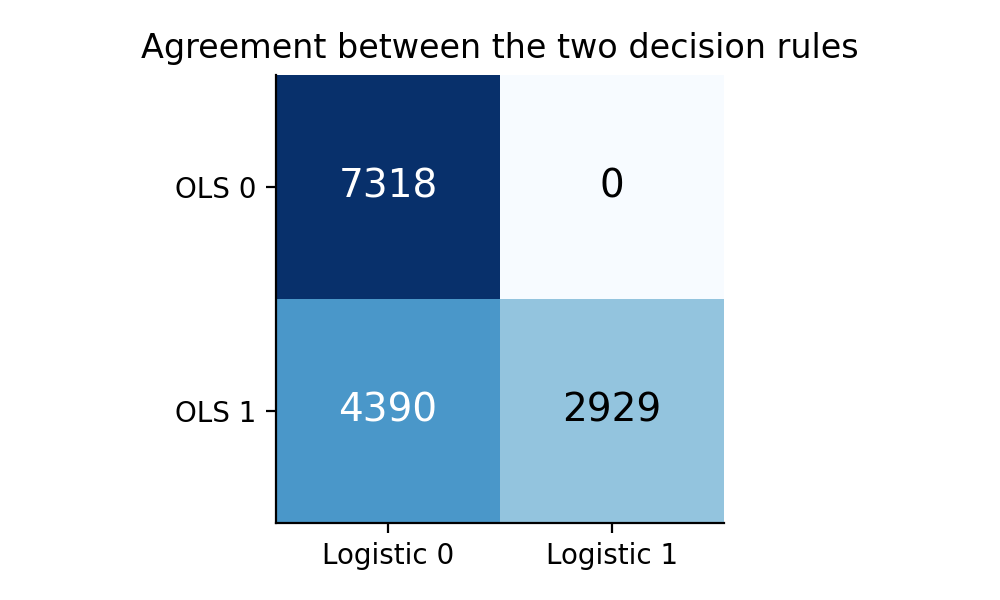

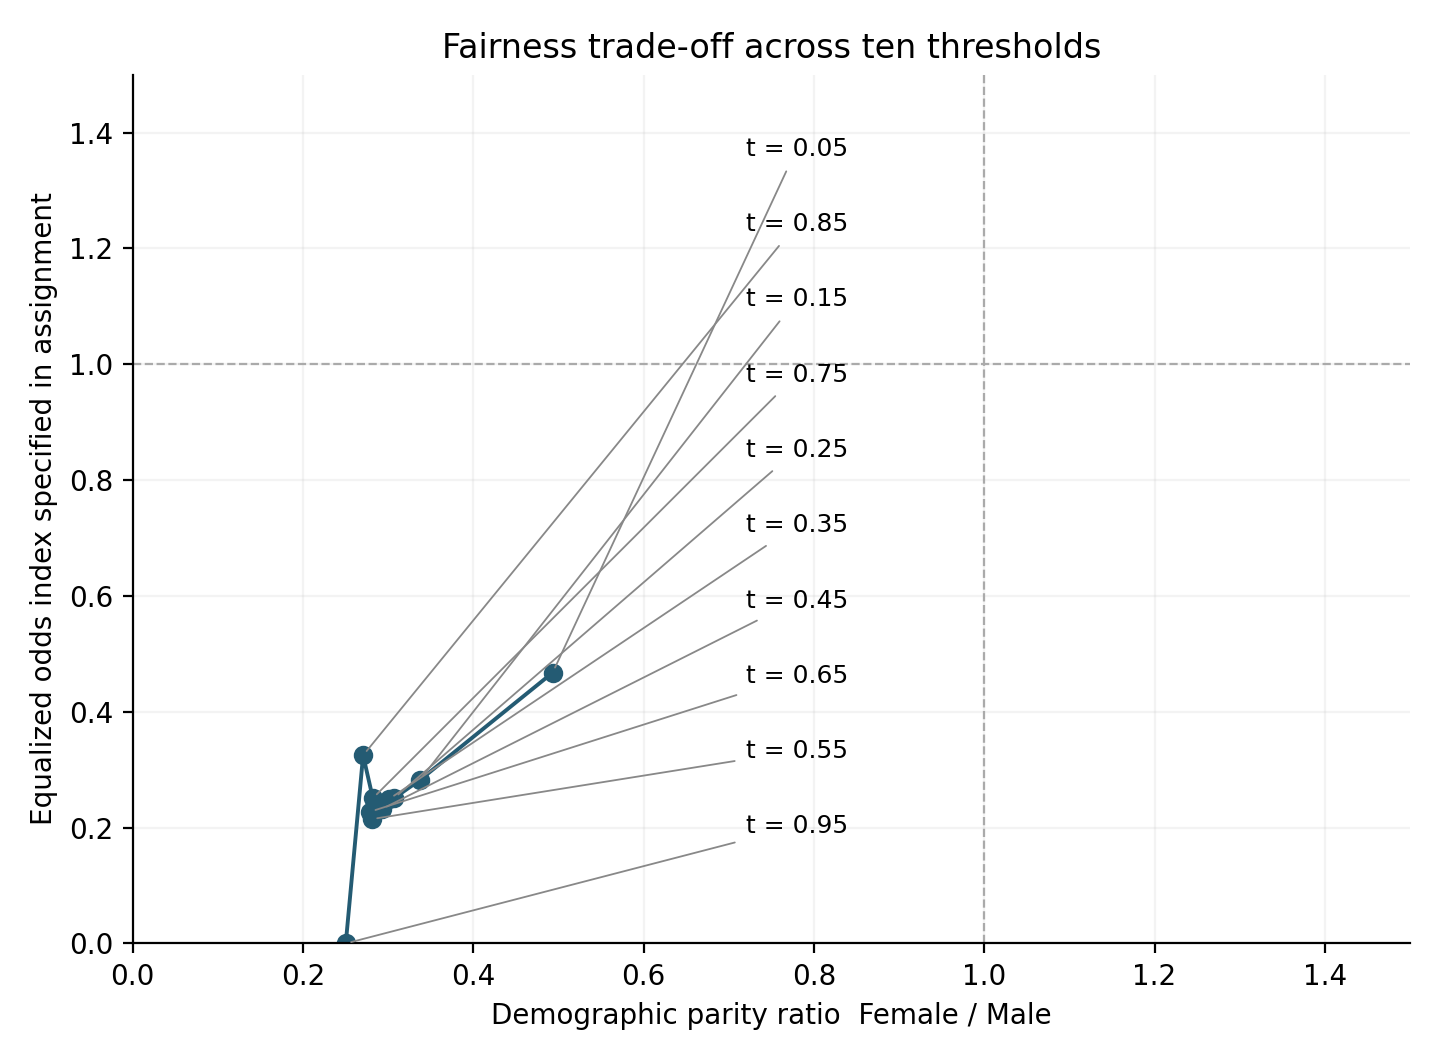

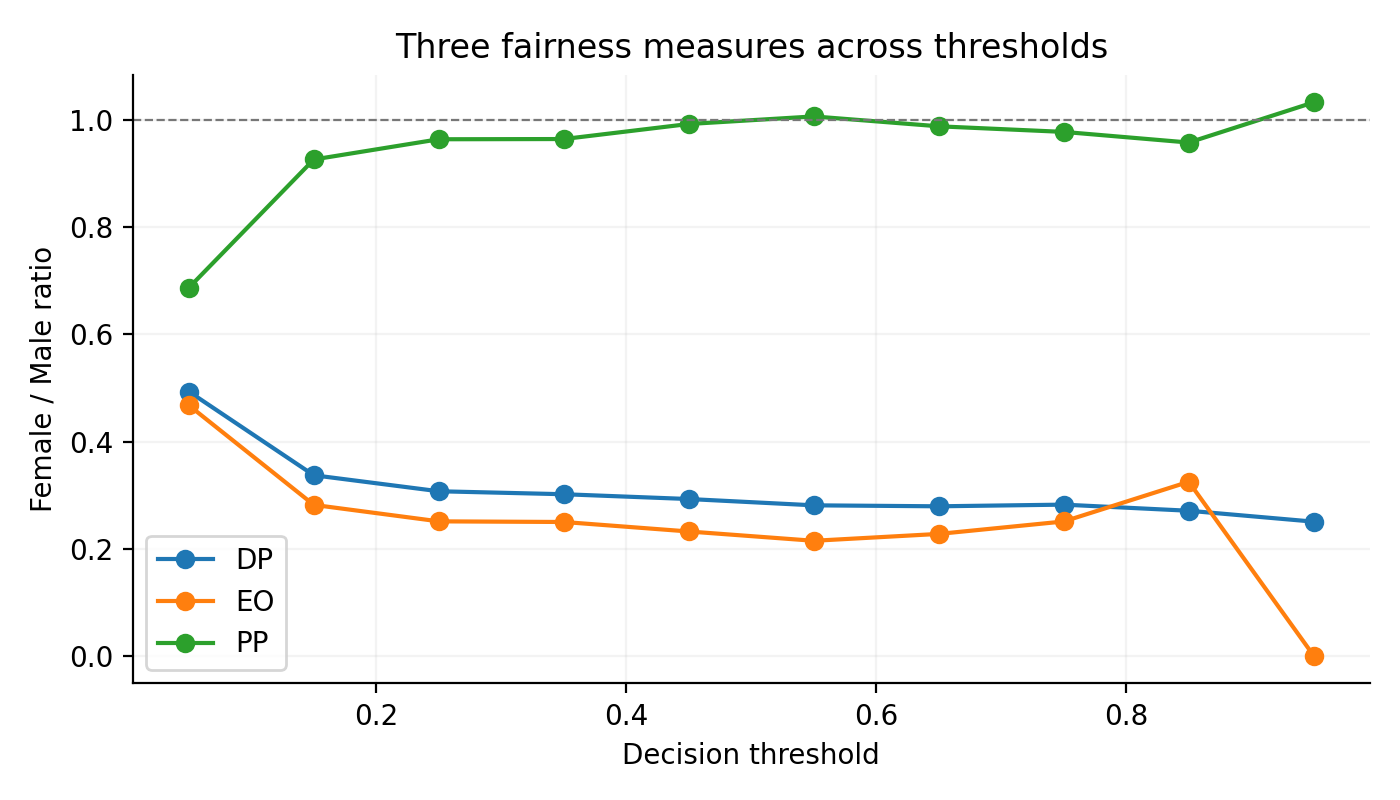

In [11]:
from IPython.display import display, Image
display(subgroup.round(6))
display(omit_key.round(6))
display(demo.round(3))
display(fair.round(6))
display(cases)
for filename in ['agreement_matrix.png','fairness_tradeoff.png','fairness_by_threshold.png']:
    display(Image(filename=str(OUT/filename)))